In [1]:
print("hello")

hello


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks']


In [6]:
import os

PROJECT_DIR = '/content/drive/MyDrive/AquaVision-AI'

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/AquaVision-AI


In [5]:
!nvidia-smi

Fri Sep 25 08:09:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

BASE_PATH = "/content/drive/MyDrive/AquaVision-AI/Data"

RAW_PATH = f"{BASE_PATH}/raw"
REFERENCE_PATH = f"{BASE_PATH}/references"
CHALLENGING_PATH = f"{BASE_PATH}/challenging"

print("Raw folder exists:", os.path.exists(RAW_PATH))
print("References folder exists:", os.path.exists(REFERENCE_PATH))
print("Challenging folder exists:", os.path.exists(CHALLENGING_PATH))

Raw folder exists: True
References folder exists: True
Challenging folder exists: True


In [3]:
def count_files(path):
    return len([
        f for f in os.listdir(path)
        if os.path.isfile(os.path.join(path, f))
    ])

print("Raw images:", count_files(RAW_PATH))
print("Reference images:", count_files(REFERENCE_PATH))
print("Challenging images:", count_files(CHALLENGING_PATH))

Raw images: 890
Reference images: 890
Challenging images: 60


In [4]:
import os

def get_image_files(folder):
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

    return sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(valid_extensions)
    ])

raw_files = get_image_files(RAW_PATH)
reference_files = get_image_files(REFERENCE_PATH)

print("Raw images:", len(raw_files))
print("Reference images:", len(reference_files))

# Compare filenames
raw_names = {os.path.splitext(f)[0] for f in raw_files}
reference_names = {os.path.splitext(f)[0] for f in reference_files}

missing_references = raw_names - reference_names
missing_raw = reference_names - raw_names

print("\nMissing reference images:", len(missing_references))
print("Missing raw images:", len(missing_raw))

if len(missing_references) == 0 and len(missing_raw) == 0:
    print("\n✅ All raw images have matching reference filenames.")
else:
    print("\n⚠️ Filename mismatch detected.")

    if missing_references:
        print("\nRaw images without references:")
        print(list(missing_references)[:20])

    if missing_raw:
        print("\nReferences without raw images:")
        print(list(missing_raw)[:20])

Raw images: 890
Reference images: 890

Missing reference images: 0
Missing raw images: 0

✅ All raw images have matching reference filenames.


In [5]:
from PIL import Image
import os

def inspect_images(folder, name, n=5):
    files = get_image_files(folder)

    print(f"\n{name}")
    print("-" * 50)

    for filename in files[:n]:
        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                print(
                    filename,
                    "→",
                    "size:", img.size,
                    "mode:", img.mode,
                    "format:", img.format
                )
        except Exception as e:
            print(filename, "→ ERROR:", e)

inspect_images(RAW_PATH, "RAW IMAGES")
inspect_images(REFERENCE_PATH, "REFERENCE IMAGES")
inspect_images(CHALLENGING_PATH, "CHALLENGING IMAGES")


RAW IMAGES
--------------------------------------------------
100_img_.png → size: (800, 450) mode: RGB format: PNG
10139.png → size: (640, 360) mode: RGB format: PNG
10151.png → size: (640, 360) mode: RGB format: PNG
101_img_.png → size: (550, 363) mode: RGB format: PNG
102_img_.png → size: (750, 562) mode: RGB format: PNG

REFERENCE IMAGES
--------------------------------------------------
100_img_.png → size: (800, 450) mode: RGB format: PNG
10139.png → size: (640, 360) mode: RGB format: PNG
10151.png → size: (640, 360) mode: RGB format: PNG
101_img_.png → size: (550, 363) mode: RGB format: PNG
102_img_.png → size: (750, 562) mode: RGB format: PNG

CHALLENGING IMAGES
--------------------------------------------------
100001.png → size: (1280, 720) mode: RGB format: JPEG
10091.png → size: (640, 360) mode: RGB format: PNG
10103.png → size: (640, 360) mode: RGB format: PNG
10167.png → size: (1280, 720) mode: RGB format: PNG
102.png → size: (1280, 720) mode: RGB format: PNG


In [6]:
def check_corrupted(folder):
    corrupted = []

    for filename in get_image_files(folder):
        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            corrupted.append(filename)

    return corrupted

print("Checking raw...")
raw_corrupted = check_corrupted(RAW_PATH)

print("Checking references...")
ref_corrupted = check_corrupted(REFERENCE_PATH)

print("Checking challenging...")
challenging_corrupted = check_corrupted(CHALLENGING_PATH)

print("\nCorrupted raw:", len(raw_corrupted))
print("Corrupted references:", len(ref_corrupted))
print("Corrupted challenging:", len(challenging_corrupted))

Checking raw...
Checking references...
Checking challenging...

Corrupted raw: 0
Corrupted references: 0
Corrupted challenging: 0


In [7]:
from collections import Counter

raw_sizes = Counter()
ref_sizes = Counter()
mismatched_sizes = []

for filename in raw_files:
    raw_path = os.path.join(RAW_PATH, filename)
    ref_path = os.path.join(REFERENCE_PATH, filename)

    with Image.open(raw_path) as raw_img:
        raw_size = raw_img.size

    with Image.open(ref_path) as ref_img:
        ref_size = ref_img.size

    raw_sizes[raw_size] += 1
    ref_sizes[ref_size] += 1

    if raw_size != ref_size:
        mismatched_sizes.append(
            (filename, raw_size, ref_size)
        )

print("Different raw image dimensions:", len(raw_sizes))
print("Different reference dimensions:", len(ref_sizes))

print("\nRaw/Reference dimension mismatches:", len(mismatched_sizes))

if mismatched_sizes:
    print("\nFirst 10 mismatches:")
    for item in mismatched_sizes[:10]:
        print(item)
else:
    print("✅ Every raw image has the same dimensions as its reference.")

Different raw image dimensions: 289
Different reference dimensions: 289

Raw/Reference dimension mismatches: 0
✅ Every raw image has the same dimensions as its reference.


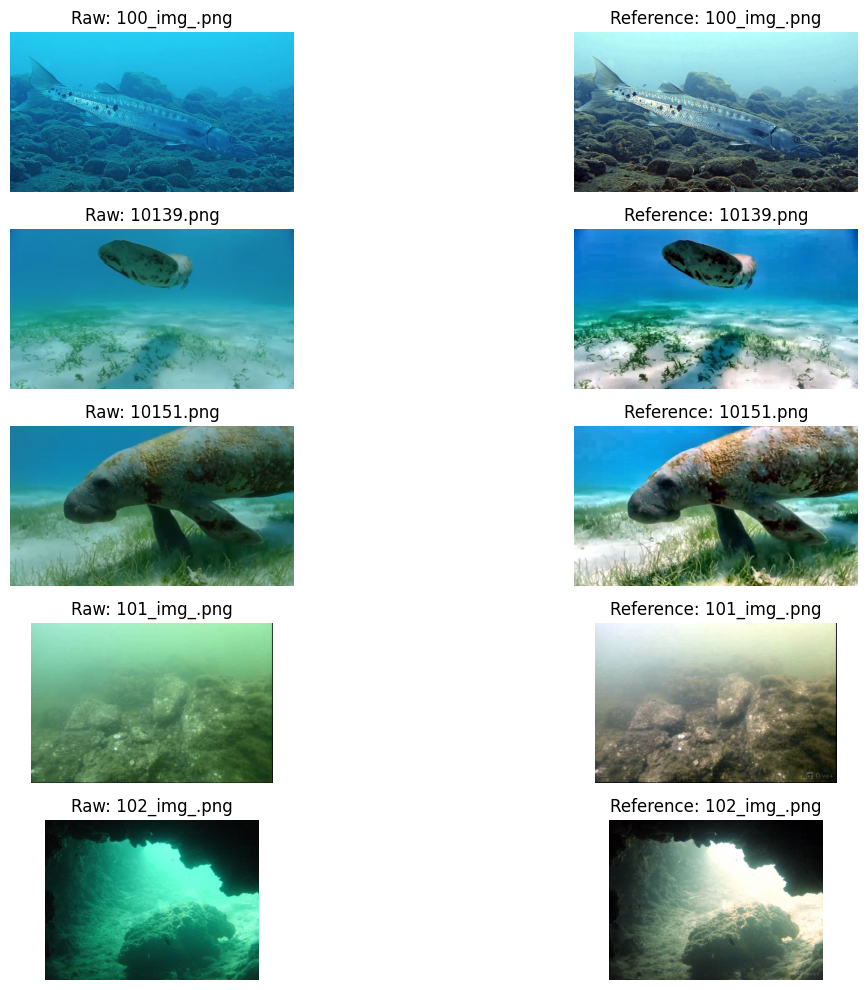

In [8]:
import matplotlib.pyplot as plt

sample_files = raw_files[:5]

plt.figure(figsize=(14, 10))

for i, filename in enumerate(sample_files):
    raw_path = os.path.join(RAW_PATH, filename)
    ref_path = os.path.join(REFERENCE_PATH, filename)

    raw_img = Image.open(raw_path)
    ref_img = Image.open(ref_path)

    # Raw
    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(raw_img)
    plt.title(f"Raw: {filename}")
    plt.axis("off")

    # Reference
    plt.subplot(5, 2, 2*i + 2)
    plt.imshow(ref_img)
    plt.title(f"Reference: {filename}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
from collections import Counter

widths = []
heights = []

for filename in raw_files:
    path = os.path.join(RAW_PATH, filename)

    with Image.open(path) as img:
        w, h = img.size

    widths.append(w)
    heights.append(h)

print("Minimum width :", min(widths))
print("Maximum width :", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

print("\nImages smaller than 256×256:")

small_images = []

for filename in raw_files:
    path = os.path.join(RAW_PATH, filename)

    with Image.open(path) as img:
        w, h = img.size

    if w < 256 or h < 256:
        small_images.append((filename, w, h))

print("Count:", len(small_images))

for item in small_images[:20]:
    print(item)

Minimum width : 225
Maximum width : 2180
Minimum height: 159
Maximum height: 1450

Images smaller than 256×256:
Count: 70
('111_img_.png', 500, 248)
('282_img_.png', 294, 171)
('284_img_.png', 276, 182)
('288_img_.png', 259, 194)
('290_img_.png', 310, 163)
('292_img_.png', 259, 194)
('293_img_.png', 259, 194)
('294_img_.png', 286, 176)
('295_img_.png', 300, 168)
('299_img_.png', 239, 211)
('300_img_.png', 276, 183)
('301_img_.png', 313, 161)
('302_img_.png', 300, 168)
('303_img_.png', 275, 183)
('304_img_.png', 259, 194)
('305_img_.png', 275, 183)
('306_img_.png', 300, 168)
('307_img_.png', 300, 168)
('311_img_.png', 275, 183)
('312_img_.png', 318, 159)


In [10]:
from collections import Counter

# Count the minimum dimension of every image
min_dimensions = []

for filename in raw_files:
    path = os.path.join(RAW_PATH, filename)

    with Image.open(path) as img:
        w, h = img.size

    min_dimensions.append(min(w, h))

print("Minimum dimension distribution:")
print("================================")

ranges = [
    (0, 159),
    (160, 191),
    (192, 223),
    (224, 255),
    (256, 319),
    (320, 383),
    (384, 511),
    (512, 9999)
]

for low, high in ranges:
    count = sum(low <= x <= high for x in min_dimensions)
    print(f"{low:4d} - {high:4d}: {count} images")

Minimum dimension distribution:
   0 -  159: 3 images
 160 -  191: 47 images
 192 -  223: 16 images
 224 -  255: 4 images
 256 -  319: 19 images
 320 -  383: 151 images
 384 -  511: 236 images
 512 - 9999: 414 images


In [11]:
import os
import random
import pandas as pd

# Reproducibility
SEED = 42
random.seed(SEED)

# Get valid image filenames
image_files = get_image_files(RAW_PATH)

# Make sure we have exactly 890 pairs
assert len(image_files) == 890, f"Expected 890 images, found {len(image_files)}"

# Shuffle filenames reproducibly
image_files = image_files.copy()
random.shuffle(image_files)

# Calculate split sizes
n_total = len(image_files)

n_train = int(0.80 * n_total)
n_val = int(0.10 * n_total)

train_files = image_files[:n_train]
val_files = image_files[n_train:n_train + n_val]
test_files = image_files[n_train + n_val:]

print("Total :", len(image_files))
print("Train :", len(train_files))
print("Val   :", len(val_files))
print("Test  :", len(test_files))

# Create split directory
SPLIT_DIR = "/content/drive/MyDrive/AquaVision-AI/data_splits"
os.makedirs(SPLIT_DIR, exist_ok=True)

# Save splits
pd.DataFrame({"filename": train_files}).to_csv(
    os.path.join(SPLIT_DIR, "train.csv"),
    index=False
)

pd.DataFrame({"filename": val_files}).to_csv(
    os.path.join(SPLIT_DIR, "val.csv"),
    index=False
)

pd.DataFrame({"filename": test_files}).to_csv(
    os.path.join(SPLIT_DIR, "test.csv"),
    index=False
)

print("\n✅ Split files saved to:")
print(SPLIT_DIR)

Total : 890
Train : 712
Val   : 89
Test  : 89

✅ Split files saved to:
/content/drive/MyDrive/AquaVision-AI/data_splits


In [12]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU available: True
GPU: Tesla T4


In [16]:
import os
import random
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF


class UIEBDataset(Dataset):

    def __init__(
        self,
        csv_file,
        raw_dir,
        reference_dir,
        crop_size=256,
        training=False
    ):
        self.data = pd.read_csv(csv_file)

        self.raw_dir = raw_dir
        self.reference_dir = reference_dir

        self.crop_size = crop_size
        self.training = training

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        filename = self.data.iloc[index]["filename"]

        raw_path = os.path.join(self.raw_dir, filename)
        reference_path = os.path.join(
            self.reference_dir,
            filename
        )

        # Load images
        raw = Image.open(raw_path).convert("RGB")
        reference = Image.open(reference_path).convert("RGB")

        # ------------------------------------------------
        # TRAINING
        # ------------------------------------------------
        if self.training:

            width, height = raw.size

            # If image is smaller than crop size,
            # enlarge BOTH images proportionally.
            if width < self.crop_size or height < self.crop_size:

                scale = max(
                    self.crop_size / width,
                    self.crop_size / height
                )

                new_width = int(round(width * scale))
                new_height = int(round(height * scale))

                raw = raw.resize(
                    (new_width, new_height),
                    Image.Resampling.BICUBIC
                )

                reference = reference.resize(
                    (new_width, new_height),
                    Image.Resampling.BICUBIC
                )

                width, height = raw.size

            # Random crop coordinates
            top = random.randint(
                0,
                height - self.crop_size
            )

            left = random.randint(
                0,
                width - self.crop_size
            )

            # SAME crop for both images
            raw = TF.crop(
                raw,
                top,
                left,
                self.crop_size,
                self.crop_size
            )

            reference = TF.crop(
                reference,
                top,
                left,
                self.crop_size,
                self.crop_size
            )

        # ------------------------------------------------
        # Convert to tensors
        # ------------------------------------------------

        raw = TF.to_tensor(raw)
        reference = TF.to_tensor(reference)

        return raw, reference, filename

In [14]:
TRAIN_CSV = "/content/drive/MyDrive/AquaVision-AI/data_splits/train.csv"

train_dataset = UIEBDataset(
    csv_file=TRAIN_CSV,
    raw_dir=RAW_PATH,
    reference_dir=REFERENCE_PATH,
    crop_size=256,
    training=True
)

print("Training samples:", len(train_dataset))

Training samples: 712


In [15]:
raw_tensor, reference_tensor, filename = train_dataset[0]

print("Filename:", filename)
print("Raw tensor shape:", raw_tensor.shape)
print("Reference tensor shape:", reference_tensor.shape)
print("Raw min:", raw_tensor.min().item())
print("Raw max:", raw_tensor.max().item())

Filename: 490_img_.png
Raw tensor shape: torch.Size([3, 256, 256])
Reference tensor shape: torch.Size([3, 256, 256])
Raw min: 0.0
Raw max: 1.0


In [17]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Number of batches:", len(train_loader))

Number of batches: 89


In [18]:
raw_batch, reference_batch, filenames = next(iter(train_loader))

print("Raw batch shape:")
print(raw_batch.shape)

print("\nReference batch shape:")
print(reference_batch.shape)

print("\nNumber of filenames:")
print(len(filenames))

print("\nFirst filenames:")
print(filenames[:5])

Raw batch shape:
torch.Size([8, 3, 256, 256])

Reference batch shape:
torch.Size([8, 3, 256, 256])

Number of filenames:
8

First filenames:
('1539.png', '276_img_.png', '185_img_.png', '361_img_.png', '238_img_.png')


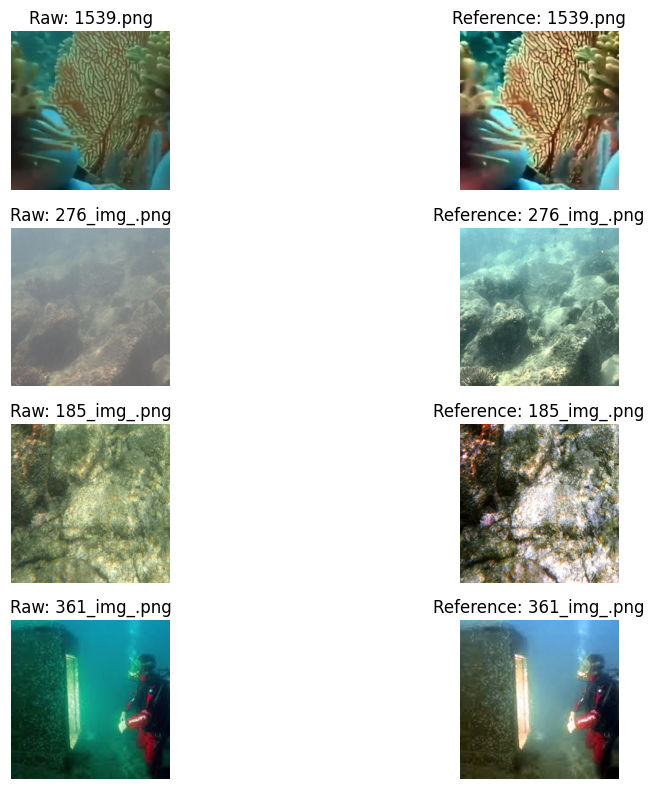

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(4):

    raw_image = raw_batch[i].permute(1, 2, 0).numpy()
    reference_image = reference_batch[i].permute(1, 2, 0).numpy()

    # Raw
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(raw_image)
    plt.title(f"Raw: {filenames[i]}")
    plt.axis("off")

    # Reference
    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(reference_image)
    plt.title(f"Reference: {filenames[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Creating model


In [20]:
import torch
import torch.nn as nn


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class EnhancementUNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(256, 512)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )

        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.dec1 = ConvBlock(128, 64)

        # Output
        self.output = nn.Conv2d(
            64,
            3,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e3)
        )

        # Decoder
        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        # Output
        output = self.output(d1)

        # Keep output in [0, 1]
        output = torch.sigmoid(output)

        return output

In [21]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = EnhancementUNet().to(device)

print("Device:", device)
print("Model created successfully.")

Device: cuda
Model created successfully.


In [22]:
# Take one batch from our DataLoader
raw_batch, reference_batch, filenames = next(iter(train_loader))

raw_batch = raw_batch.to(device)

with torch.no_grad():
    output = model(raw_batch)

print("Input shape :", raw_batch.shape)
print("Output shape:", output.shape)
print("Output min  :", output.min().item())
print("Output max  :", output.max().item())

Input shape : torch.Size([8, 3, 256, 256])
Output shape: torch.Size([8, 3, 256, 256])
Output min  : 0.5013519525527954
Output max  : 0.5287026166915894


In [23]:
import torch.nn as nn

# Loss function
criterion = nn.L1Loss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 1e-4)

Loss function: L1Loss()
Optimizer: Adam
Learning rate: 0.0001


In [24]:
model.train()

smoke_test_batches = 5

for batch_idx, (raw_batch, reference_batch, filenames) in enumerate(train_loader):

    if batch_idx >= smoke_test_batches:
        break

    raw_batch = raw_batch.to(device, non_blocking=True)
    reference_batch = reference_batch.to(device, non_blocking=True)

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    output = model(raw_batch)

    # Calculate loss
    loss = criterion(output, reference_batch)

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()

    print(
        f"Batch {batch_idx + 1}/{smoke_test_batches} "
        f"| Loss: {loss.item():.6f}"
    )

Batch 1/5 | Loss: 0.199036
Batch 2/5 | Loss: 0.247565
Batch 3/5 | Loss: 0.204268
Batch 4/5 | Loss: 0.201760
Batch 5/5 | Loss: 0.196092


In [25]:
class UIEBValidationDataset(Dataset):

    def __init__(
        self,
        csv_file,
        raw_dir,
        reference_dir,
        crop_size=256
    ):
        self.data = pd.read_csv(csv_file)

        self.raw_dir = raw_dir
        self.reference_dir = reference_dir
        self.crop_size = crop_size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        filename = self.data.iloc[index]["filename"]

        raw_path = os.path.join(
            self.raw_dir,
            filename
        )

        reference_path = os.path.join(
            self.reference_dir,
            filename
        )

        raw = Image.open(raw_path).convert("RGB")
        reference = Image.open(reference_path).convert("RGB")

        # Resize both images using the same scale
        width, height = raw.size

        scale = max(
            self.crop_size / width,
            self.crop_size / height
        )

        new_width = int(round(width * scale))
        new_height = int(round(height * scale))

        raw = raw.resize(
            (new_width, new_height),
            Image.Resampling.BICUBIC
        )

        reference = reference.resize(
            (new_width, new_height),
            Image.Resampling.BICUBIC
        )

        # Center crop — SAME crop for both
        left = (new_width - self.crop_size) // 2
        top = (new_height - self.crop_size) // 2

        raw = TF.crop(
            raw,
            top,
            left,
            self.crop_size,
            self.crop_size
        )

        reference = TF.crop(
            reference,
            top,
            left,
            self.crop_size,
            self.crop_size
        )

        # Convert to tensors
        raw = TF.to_tensor(raw)
        reference = TF.to_tensor(reference)

        return raw, reference, filename

In [26]:
VAL_CSV = "/content/drive/MyDrive/AquaVision-AI/data_splits/val.csv"

val_dataset = UIEBValidationDataset(
    csv_file=VAL_CSV,
    raw_dir=RAW_PATH,
    reference_dir=REFERENCE_PATH,
    crop_size=256
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Validation samples:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation samples: 89
Validation batches: 12


In [27]:
def validate_model(model, val_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for raw_batch, reference_batch, filenames in val_loader:

            raw_batch = raw_batch.to(
                device,
                non_blocking=True
            )

            reference_batch = reference_batch.to(
                device,
                non_blocking=True
            )

            output = model(raw_batch)

            loss = criterion(
                output,
                reference_batch
            )

            batch_size = raw_batch.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

    average_loss = total_loss / total_samples

    return average_loss

In [28]:
val_loss = validate_model(
    model,
    val_loader,
    criterion,
    device
)

print("Validation loss:", val_loss)

Validation loss: 0.22866936915376213


In [29]:
# Reinitialize the model from scratch

model = EnhancementUNet().to(device)

# Recreate optimizer for the new model
criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("✅ Model reset.")
print("Device:", device)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 1e-4)

✅ Model reset.
Device: cuda
Optimizer: Adam
Learning rate: 0.0001


In [30]:
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/AquaVision-AI/models/enhancement"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Checkpoint directory:")
print(CHECKPOINT_DIR)

Checkpoint directory:
/content/drive/MyDrive/AquaVision-AI/models/enhancement


In [31]:
import time

NUM_EPOCHS = 3

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # ==========================================
    # TRAINING
    # ==========================================

    model.train()

    running_train_loss = 0.0
    total_train_samples = 0

    for raw_batch, reference_batch, filenames in train_loader:

        raw_batch = raw_batch.to(
            device,
            non_blocking=True
        )

        reference_batch = reference_batch.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        output = model(raw_batch)

        # Calculate loss
        loss = criterion(
            output,
            reference_batch
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        batch_size = raw_batch.size(0)

        running_train_loss += (
            loss.item() * batch_size
        )

        total_train_samples += batch_size

    train_loss = (
        running_train_loss /
        total_train_samples
    )

    # ==========================================
    # VALIDATION
    # ==========================================

    val_loss = validate_model(
        model,
        val_loader,
        criterion,
        device
    )

    # Save history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # ==========================================
    # CHECKPOINT
    # ==========================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "val_loss": val_loss
            },
            os.path.join(
                CHECKPOINT_DIR,
                "best_model.pth"
            )
        )

        checkpoint_status = "⭐ BEST MODEL SAVED"

    else:
        checkpoint_status = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.6f} "
        f"| Val Loss: {val_loss:.6f} "
        f"| Time: {elapsed:.1f}s "
        f"{checkpoint_status}"
    )

print("\nTraining trial completed.")
print("Best validation loss:", best_val_loss)

Epoch [1/3] | Train Loss: 0.186781 | Val Loss: 0.151926 | Time: 53.4s ⭐ BEST MODEL SAVED
Epoch [2/3] | Train Loss: 0.140411 | Val Loss: 0.127196 | Time: 56.0s ⭐ BEST MODEL SAVED
Epoch [3/3] | Train Loss: 0.121330 | Val Loss: 0.112563 | Time: 57.4s ⭐ BEST MODEL SAVED

Training trial completed.
Best validation loss: 0.11256324374273921


In [32]:
checkpoint_path = "/content/drive/MyDrive/AquaVision-AI/models/enhancement/best_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("✅ Best model loaded")
print("Epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])
print("Validation loss:", checkpoint["val_loss"])

✅ Best model loaded
Epoch: 3
Training loss: 0.12132959193393086
Validation loss: 0.11256324374273921


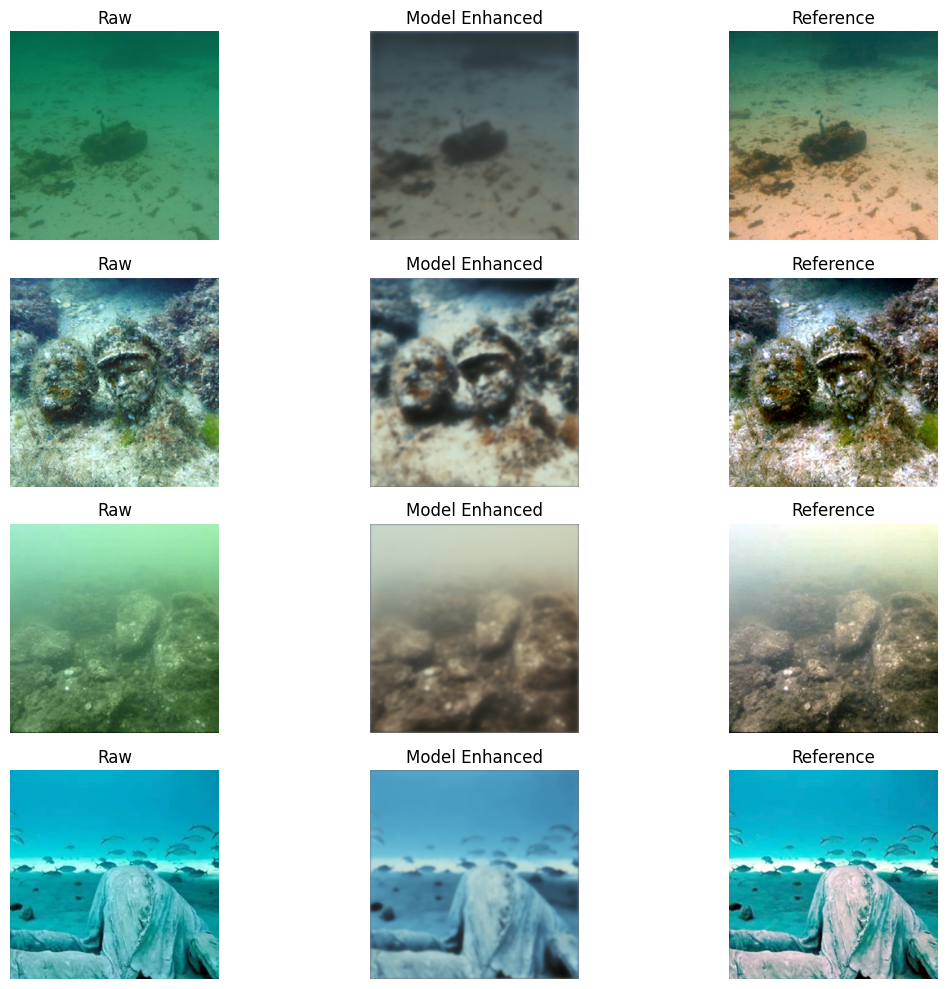

In [33]:
import matplotlib.pyplot as plt

raw_batch, reference_batch, filenames = next(iter(val_loader))

raw_batch_gpu = raw_batch.to(device)

with torch.no_grad():
    enhanced_batch = model(raw_batch_gpu)

enhanced_batch = enhanced_batch.cpu()

plt.figure(figsize=(12, 10))

for i in range(4):

    raw_image = raw_batch[i].permute(1, 2, 0).numpy()
    enhanced_image = enhanced_batch[i].permute(1, 2, 0).numpy()
    reference_image = reference_batch[i].permute(1, 2, 0).numpy()

    # Raw
    plt.subplot(4, 3, 3*i + 1)
    plt.imshow(raw_image)
    plt.title("Raw")
    plt.axis("off")

    # Enhanced
    plt.subplot(4, 3, 3*i + 2)
    plt.imshow(enhanced_image)
    plt.title("Model Enhanced")
    plt.axis("off")

    # Reference
    plt.subplot(4, 3, 3*i + 3)
    plt.imshow(reference_image)
    plt.title("Reference")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
model = EnhancementUNet().to(device)

criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("✅ Baseline model reset.")

✅ Baseline model reset.


In [35]:
BASELINE_CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "AquaVision-AI/models/enhancement/baseline_l1"
)

os.makedirs(
    BASELINE_CHECKPOINT_DIR,
    exist_ok=True
)

print(BASELINE_CHECKPOINT_DIR)

/content/drive/MyDrive/AquaVision-AI/models/enhancement/baseline_l1


In [36]:
import time

NUM_EPOCHS = 20

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # ==========================
    # TRAIN
    # ==========================

    model.train()

    running_train_loss = 0.0
    total_train_samples = 0

    for raw_batch, reference_batch, filenames in train_loader:

        raw_batch = raw_batch.to(
            device,
            non_blocking=True
        )

        reference_batch = reference_batch.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        output = model(raw_batch)

        loss = criterion(
            output,
            reference_batch
        )

        loss.backward()

        optimizer.step()

        batch_size = raw_batch.size(0)

        running_train_loss += (
            loss.item() * batch_size
        )

        total_train_samples += batch_size

    train_loss = (
        running_train_loss /
        total_train_samples
    )

    # ==========================
    # VALIDATION
    # ==========================

    val_loss = validate_model(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # ==========================
    # SAVE BEST MODEL
    # ==========================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "val_loss": val_loss
            },
            os.path.join(
                BASELINE_CHECKPOINT_DIR,
                "best_model.pth"
            )
        )

        status = "⭐ BEST"

    else:
        status = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"| Train: {train_loss:.6f} "
        f"| Val: {val_loss:.6f} "
        f"| Time: {elapsed:.1f}s "
        f"{status}"
    )

print("\n✅ 20-epoch baseline training completed.")
print("Best validation loss:", best_val_loss)

Epoch [01/20] | Train: 0.182319 | Val: 0.147885 | Time: 56.3s ⭐ BEST
Epoch [02/20] | Train: 0.135052 | Val: 0.136286 | Time: 55.2s ⭐ BEST
Epoch [03/20] | Train: 0.121682 | Val: 0.113161 | Time: 57.3s ⭐ BEST
Epoch [04/20] | Train: 0.114194 | Val: 0.108020 | Time: 57.9s ⭐ BEST
Epoch [05/20] | Train: 0.109688 | Val: 0.117965 | Time: 58.1s 
Epoch [06/20] | Train: 0.110335 | Val: 0.106604 | Time: 54.3s ⭐ BEST
Epoch [07/20] | Train: 0.107187 | Val: 0.104909 | Time: 57.0s ⭐ BEST
Epoch [08/20] | Train: 0.109596 | Val: 0.105238 | Time: 57.9s 
Epoch [09/20] | Train: 0.107313 | Val: 0.111442 | Time: 54.8s 
Epoch [10/20] | Train: 0.106001 | Val: 0.102219 | Time: 54.7s ⭐ BEST
Epoch [11/20] | Train: 0.104459 | Val: 0.100364 | Time: 57.5s ⭐ BEST
Epoch [12/20] | Train: 0.104082 | Val: 0.098594 | Time: 58.8s ⭐ BEST
Epoch [13/20] | Train: 0.103228 | Val: 0.101662 | Time: 57.7s 
Epoch [14/20] | Train: 0.101089 | Val: 0.101416 | Time: 53.6s 
Epoch [15/20] | Train: 0.101592 | Val: 0.097963 | Time: 55.3s ⭐ 

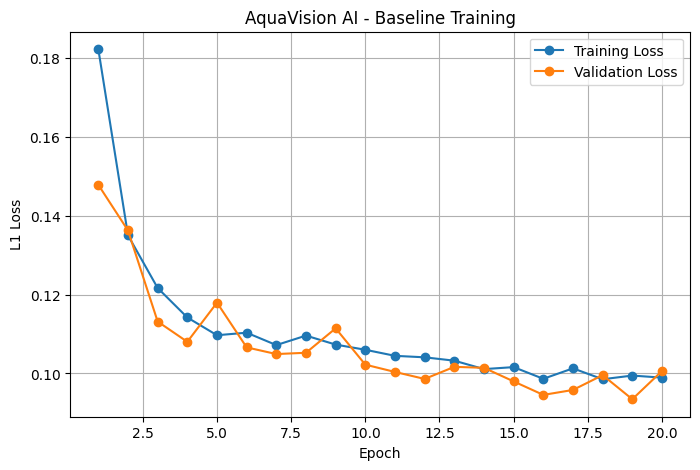

In [37]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("L1 Loss")
plt.title("AquaVision AI - Baseline Training")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
BEST_BASELINE_PATH = (
    "/content/drive/MyDrive/"
    "AquaVision-AI/models/enhancement/"
    "baseline_l1/best_model.pth"
)

checkpoint = torch.load(
    BEST_BASELINE_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("✅ Best baseline model loaded")
print("Best epoch:", checkpoint["epoch"])
print("Train loss:", checkpoint["train_loss"])
print("Validation loss:", checkpoint["val_loss"])

✅ Best baseline model loaded
Best epoch: 19
Train loss: 0.09944702961136785
Validation loss: 0.0934406290395876


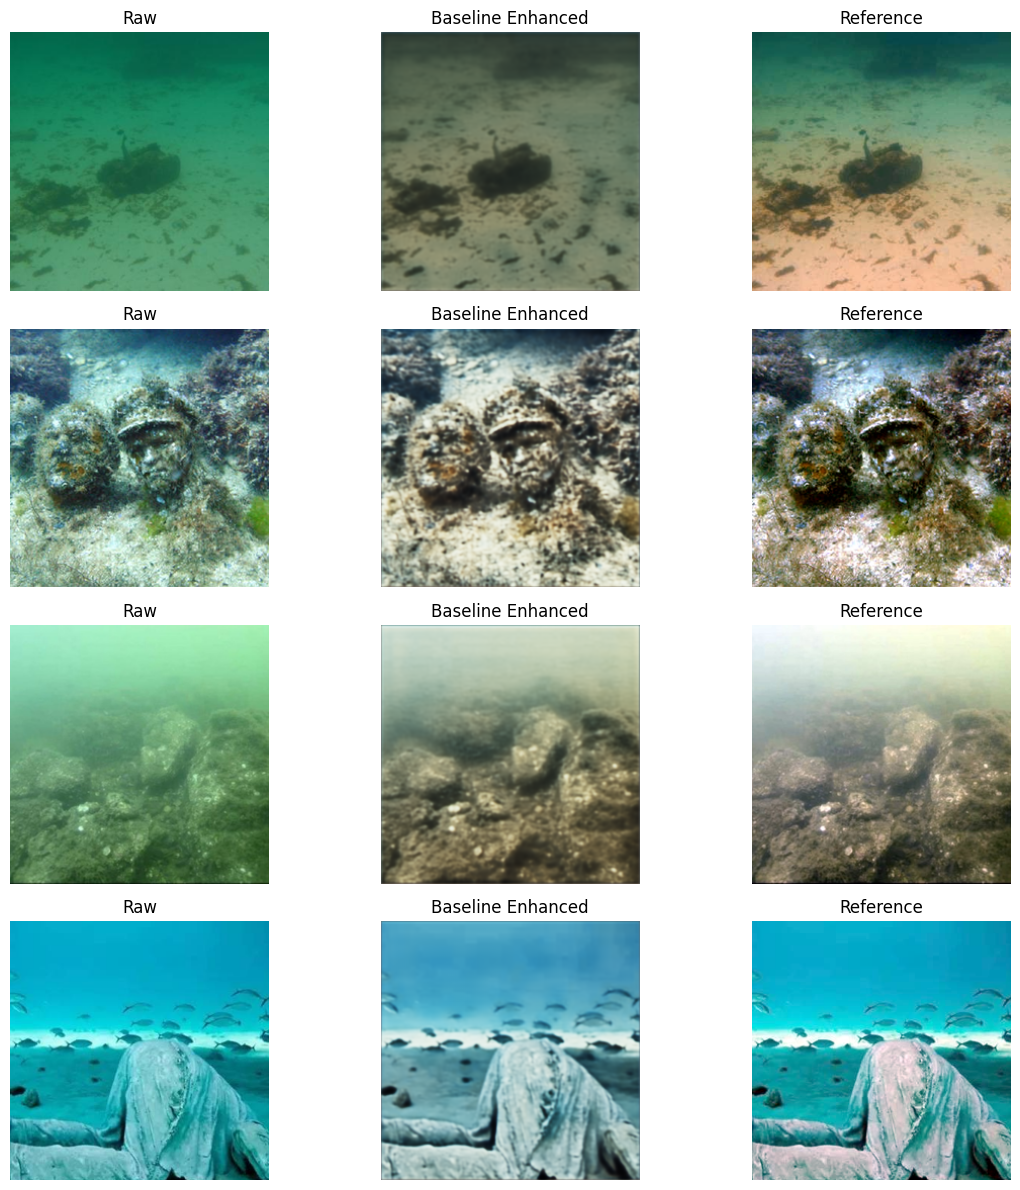

In [39]:
raw_batch, reference_batch, filenames = next(iter(val_loader))

raw_gpu = raw_batch.to(device)

with torch.no_grad():
    enhanced_batch = model(raw_gpu)

enhanced_batch = enhanced_batch.cpu()

plt.figure(figsize=(12, 12))

for i in range(4):

    raw_image = raw_batch[i].permute(1, 2, 0).numpy()
    enhanced_image = enhanced_batch[i].permute(1, 2, 0).numpy()
    reference_image = reference_batch[i].permute(1, 2, 0).numpy()

    plt.subplot(4, 3, 3*i + 1)
    plt.imshow(raw_image)
    plt.title("Raw")
    plt.axis("off")

    plt.subplot(4, 3, 3*i + 2)
    plt.imshow(enhanced_image)
    plt.title("Baseline Enhanced")
    plt.axis("off")

    plt.subplot(4, 3, 3*i + 3)
    plt.imshow(reference_image)
    plt.title("Reference")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [40]:
!pip install -q scikit-image

In [41]:
from skimage.metrics import structural_similarity
import numpy as np

In [42]:
TEST_CSV = "/content/drive/MyDrive/AquaVision-AI/data_splits/test.csv"

test_df = pd.read_csv(TEST_CSV)

print("Test images:", len(test_df))

Test images: 89


In [43]:
import math
import numpy as np
import torch.nn.functional as F


def load_image_for_model(path):
    """
    Load an image and pad it so its height and width
    are divisible by 8.

    The original size is returned so we can remove
    the padding after inference.
    """

    image = Image.open(path).convert("RGB")

    original_width, original_height = image.size

    tensor = TF.to_tensor(image).unsqueeze(0)

    _, _, height, width = tensor.shape

    pad_h = (8 - height % 8) % 8
    pad_w = (8 - width % 8) % 8

    if pad_h > 0 or pad_w > 0:
        tensor = F.pad(
            tensor,
            (0, pad_w, 0, pad_h),
            mode="reflect"
        )

    return tensor, original_width, original_height

In [44]:
def calculate_psnr(prediction, target):
    """
    prediction and target:
    numpy arrays in [0, 1]
    """

    mse = np.mean(
        (prediction - target) ** 2
    )

    if mse == 0:
        return float("inf")

    return 10 * math.log10(
        1.0 / mse
    )

In [45]:
model.eval()

raw_psnr_values = []
enhanced_psnr_values = []

raw_ssim_values = []
enhanced_ssim_values = []

test_results = []

with torch.no_grad():

    for index, row in test_df.iterrows():

        filename = row["filename"]

        raw_path = os.path.join(
            RAW_PATH,
            filename
        )

        reference_path = os.path.join(
            REFERENCE_PATH,
            filename
        )

        # --------------------------------
        # Load raw and reference
        # --------------------------------

        raw_image = Image.open(
            raw_path
        ).convert("RGB")

        reference_image = Image.open(
            reference_path
        ).convert("RGB")

        # Convert reference to numpy [0,1]
        reference_np = np.asarray(
            reference_image
        ).astype(np.float32) / 255.0

        raw_np = np.asarray(
            raw_image
        ).astype(np.float32) / 255.0

        # --------------------------------
        # Raw baseline metrics
        # --------------------------------

        raw_psnr = calculate_psnr(
            raw_np,
            reference_np
        )

        raw_ssim = structural_similarity(
            raw_np,
            reference_np,
            channel_axis=-1,
            data_range=1.0
        )

        # --------------------------------
        # Prepare raw image for model
        # --------------------------------

        input_tensor, original_width, original_height = (
            load_image_for_model(raw_path)
        )

        input_tensor = input_tensor.to(device)

        # --------------------------------
        # Model inference
        # --------------------------------

        enhanced_tensor = model(
            input_tensor
        )

        # Remove padding
        enhanced_tensor = enhanced_tensor[
            :,
            :,
            :original_height,
            :original_width
        ]

        # Convert to numpy [H,W,C]
        enhanced_np = (
            enhanced_tensor
            .squeeze(0)
            .cpu()
            .permute(1, 2, 0)
            .numpy()
        )

        enhanced_np = np.clip(
            enhanced_np,
            0.0,
            1.0
        )

        # --------------------------------
        # Enhanced metrics
        # --------------------------------

        enhanced_psnr = calculate_psnr(
            enhanced_np,
            reference_np
        )

        enhanced_ssim = structural_similarity(
            enhanced_np,
            reference_np,
            channel_axis=-1,
            data_range=1.0
        )

        # Store
        raw_psnr_values.append(raw_psnr)
        enhanced_psnr_values.append(enhanced_psnr)

        raw_ssim_values.append(raw_ssim)
        enhanced_ssim_values.append(enhanced_ssim)

        test_results.append({
            "filename": filename,
            "raw_psnr": raw_psnr,
            "enhanced_psnr": enhanced_psnr,
            "raw_ssim": raw_ssim,
            "enhanced_ssim": enhanced_ssim
        })

        if (index + 1) % 10 == 0:
            print(
                f"Processed {index + 1}/"
                f"{len(test_df)} images"
            )

Processed 10/89 images
Processed 20/89 images
Processed 30/89 images
Processed 40/89 images
Processed 50/89 images
Processed 60/89 images
Processed 70/89 images
Processed 80/89 images


In [46]:
avg_raw_psnr = np.mean(
    raw_psnr_values
)

avg_enhanced_psnr = np.mean(
    enhanced_psnr_values
)

avg_raw_ssim = np.mean(
    raw_ssim_values
)

avg_enhanced_ssim = np.mean(
    enhanced_ssim_values
)

print("=" * 50)

print(
    f"Raw PSNR      : {avg_raw_psnr:.4f} dB"
)

print(
    f"Enhanced PSNR : {avg_enhanced_psnr:.4f} dB"
)

print(
    f"Raw SSIM      : {avg_raw_ssim:.4f}"
)

print(
    f"Enhanced SSIM : {avg_enhanced_ssim:.4f}"
)

print("=" * 50)

print(
    f"PSNR change   : "
    f"{avg_enhanced_psnr - avg_raw_psnr:+.4f} dB"
)

print(
    f"SSIM change   : "
    f"{avg_enhanced_ssim - avg_raw_ssim:+.4f}"
)

Raw PSNR      : 16.6860 dB
Enhanced PSNR : 18.4251 dB
Raw SSIM      : 0.7598
Enhanced SSIM : 0.7790
PSNR change   : +1.7391 dB
SSIM change   : +0.0192


In [47]:
!pip install -q opencv-python scikit-image

In [48]:
import cv2
from skimage import color, filters

In [49]:
def calculate_uciqe(image_rgb):
    """
    image_rgb:
        NumPy array, H x W x 3, values in [0, 1]
    """

    # Convert RGB [0,1] → LAB
    lab = color.rgb2lab(image_rgb)

    L = lab[:, :, 0]
    a = lab[:, :, 1]
    b = lab[:, :, 2]

    # Chroma
    chroma = np.sqrt(a**2 + b**2)

    # Standard deviation of chroma
    sigma_c = np.std(chroma)

    # Luminance contrast
    sorted_L = np.sort(L.flatten())

    low_index = int(0.01 * len(sorted_L))
    high_index = int(0.99 * len(sorted_L))

    contrast_l = (
        sorted_L[high_index]
        - sorted_L[low_index]
    )

    # Saturation
    saturation = np.divide(
        chroma,
        L,
        out=np.zeros_like(chroma),
        where=L != 0
    )

    mean_saturation = np.mean(saturation)

    # Standard UCIQE coefficients
    c1 = 0.4680
    c2 = 0.2745
    c3 = 0.2576

    uciqe = (
        c1 * sigma_c
        + c2 * contrast_l
        + c3 * mean_saturation
    )

    return float(uciqe)

In [50]:
def eme(channel, block_size=8):

    h, w = channel.shape

    num_x = math.ceil(h / block_size)
    num_y = math.ceil(w / block_size)

    eme_value = 0.0

    weight = 2.0 / (num_x * num_y)

    for i in range(num_x):

        x_start = i * block_size
        x_end = min(
            (i + 1) * block_size,
            h
        )

        for j in range(num_y):

            y_start = j * block_size
            y_end = min(
                (j + 1) * block_size,
                w
            )

            block = channel[
                x_start:x_end,
                y_start:y_end
            ]

            block_min = np.min(block)
            block_max = np.max(block)

            if block_min <= 0 or block_max <= 0:
                continue

            eme_value += (
                weight
                * np.log(
                    block_max / block_min
                )
            )

    return eme_value

In [51]:
def calculate_uicm(image_rgb):

    R = image_rgb[:, :, 0]
    G = image_rgb[:, :, 1]
    B = image_rgb[:, :, 2]

    rg = R - G
    yb = (R + G) / 2.0 - B

    rg_sorted = np.sort(rg.flatten())
    yb_sorted = np.sort(yb.flatten())

    trim = int(0.1 * len(rg_sorted))

    if trim > 0:
        rg_trimmed = rg_sorted[trim:-trim]
        yb_trimmed = yb_sorted[trim:-trim]
    else:
        rg_trimmed = rg_sorted
        yb_trimmed = yb_sorted

    mean_rg = np.mean(rg_trimmed)
    mean_yb = np.mean(yb_trimmed)

    var_rg = np.mean(
        (rg_trimmed - mean_rg) ** 2
    )

    var_yb = np.mean(
        (yb_trimmed - mean_yb) ** 2
    )

    uicm = (
        -0.0268
        * np.sqrt(mean_rg**2 + mean_yb**2)
        +
        0.1586
        * np.sqrt(var_rg + var_yb)
    )

    return float(uicm)

In [52]:
def calculate_uism(image_rgb):

    R = image_rgb[:, :, 0]
    G = image_rgb[:, :, 1]
    B = image_rgb[:, :, 2]

    R_edge = R * filters.sobel(R)
    G_edge = G * filters.sobel(G)
    B_edge = B * filters.sobel(B)

    R_eme = eme(R_edge)
    G_eme = eme(G_edge)
    B_eme = eme(B_edge)

    uism = (
        0.299 * R_eme
        + 0.587 * G_eme
        + 0.114 * B_eme
    )

    return float(uism)

In [53]:
def calculate_uiconm(image_rgb):

    gray = color.rgb2gray(image_rgb)

    h, w = gray.shape

    block_size = 8

    num_x = math.ceil(h / block_size)
    num_y = math.ceil(w / block_size)

    values = []

    for i in range(num_x):

        x_start = i * block_size
        x_end = min(
            (i + 1) * block_size,
            h
        )

        for j in range(num_y):

            y_start = j * block_size
            y_end = min(
                (j + 1) * block_size,
                w
            )

            block = gray[
                x_start:x_end,
                y_start:y_end
            ]

            block_min = np.min(block)
            block_max = np.max(block)

            if block_max <= 0:
                continue

            if block_min <= 0:
                block_min = 1e-6

            ratio = (
                block_max - block_min
            ) / (
                block_max + block_min
            )

            values.append(ratio)

    if len(values) == 0:
        return 0.0

    return float(np.mean(values))

In [54]:
def calculate_uiqm(image_rgb):

    uicm = calculate_uicm(image_rgb)
    uism = calculate_uism(image_rgb)
    uiconm = calculate_uiconm(image_rgb)

    uiqm = (
        0.0282 * uicm
        + 0.2953 * uism
        + 3.5753 * uiconm
    )

    return float(uiqm)

In [55]:
sample_path = os.path.join(
    RAW_PATH,
    test_df.iloc[0]["filename"]
)

sample_image = Image.open(
    sample_path
).convert("RGB")

sample_rgb = (
    np.asarray(sample_image)
    .astype(np.float32) / 255.0
)

sample_uciqe = calculate_uciqe(sample_rgb)
sample_uiqm = calculate_uiqm(sample_rgb)

print("Sample UCIQE:", sample_uciqe)
print("Sample UIQM :", sample_uiqm)

Sample UCIQE: 20.446760177612305
Sample UIQM : 2.4807163177127016


In [56]:
raw_uiqm_values = []
enhanced_uiqm_values = []

raw_uciqe_values = []
enhanced_uciqe_values = []

for index, row in test_df.iterrows():

    filename = row["filename"]

    raw_path = os.path.join(
        RAW_PATH,
        filename
    )

    # Load raw image
    raw_image = Image.open(
        raw_path
    ).convert("RGB")

    raw_np = (
        np.asarray(raw_image)
        .astype(np.float32) / 255.0
    )

    # -----------------------------
    # RAW metrics
    # -----------------------------

    raw_uiqm = calculate_uiqm(raw_np)
    raw_uciqe = calculate_uciqe(raw_np)

    # -----------------------------
    # MODEL ENHANCEMENT
    # -----------------------------

    input_tensor, original_width, original_height = (
        load_image_for_model(raw_path)
    )

    input_tensor = input_tensor.to(device)

    with torch.no_grad():
        enhanced_tensor = model(input_tensor)

    enhanced_tensor = enhanced_tensor[
        :,
        :,
        :original_height,
        :original_width
    ]

    enhanced_np = (
        enhanced_tensor
        .squeeze(0)
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    enhanced_np = np.clip(
        enhanced_np,
        0.0,
        1.0
    )

    # -----------------------------
    # ENHANCED metrics
    # -----------------------------

    enhanced_uiqm = calculate_uiqm(
        enhanced_np
    )

    enhanced_uciqe = calculate_uciqe(
        enhanced_np
    )

    raw_uiqm_values.append(raw_uiqm)
    enhanced_uiqm_values.append(enhanced_uiqm)

    raw_uciqe_values.append(raw_uciqe)
    enhanced_uciqe_values.append(enhanced_uciqe)

    if (index + 1) % 10 == 0:
        print(
            f"Processed {index + 1}/"
            f"{len(test_df)} images"
        )

print("\n✅ UIQM and UCIQE evaluation completed.")

Processed 10/89 images
Processed 20/89 images
Processed 30/89 images
Processed 40/89 images
Processed 50/89 images
Processed 60/89 images
Processed 70/89 images
Processed 80/89 images

✅ UIQM and UCIQE evaluation completed.


In [57]:
avg_raw_uiqm = np.mean(
    raw_uiqm_values
)

avg_enhanced_uiqm = np.mean(
    enhanced_uiqm_values
)

avg_raw_uciqe = np.mean(
    raw_uciqe_values
)

avg_enhanced_uciqe = np.mean(
    enhanced_uciqe_values
)

print("=" * 60)

print(
    f"Raw UIQM      : {avg_raw_uiqm:.4f}"
)

print(
    f"Enhanced UIQM : {avg_enhanced_uiqm:.4f}"
)

print()

print(
    f"Raw UCIQE      : {avg_raw_uciqe:.4f}"
)

print(
    f"Enhanced UCIQE : {avg_enhanced_uciqe:.4f}"
)

print("=" * 60)

print(
    f"UIQM change  : "
    f"{avg_enhanced_uiqm - avg_raw_uiqm:+.4f}"
)

print(
    f"UCIQE change : "
    f"{avg_enhanced_uciqe - avg_raw_uciqe:+.4f}"
)

Raw UIQM      : 2.0774
Enhanced UIQM : 2.7627

Raw UCIQE      : 21.8322
Enhanced UCIQE : 24.0636
UIQM change  : +0.6853
UCIQE change : +2.2314


In [58]:
import json
import os
from datetime import datetime

baseline_results = {
    "experiment": "Baseline_U-Net_L1",
    "dataset": "UIEB",
    "total_images": 890,
    "train_images": 712,
    "validation_images": 89,
    "test_images": 89,

    "model": "U-Net",
    "loss": "L1",
    "optimizer": "Adam",
    "epochs": 20,
    "best_epoch": 19,

    "best_validation_loss": 0.0934406290395876,

    "metrics": {
        "PSNR": {
            "raw": 16.6860,
            "enhanced": 18.4251,
            "change": 1.7391
        },
        "SSIM": {
            "raw": 0.7598,
            "enhanced": 0.7790,
            "change": 0.0192
        },
        "UIQM": {
            "raw": 2.0774,
            "enhanced": 2.7627,
            "change": 0.6853
        },
        "UCIQE": {
            "raw": 21.8322,
            "enhanced": 24.0636,
            "change": 2.2314
        }
    }
}

results_dir = (
    "/content/drive/MyDrive/"
    "AquaVision-AI/experiments"
)

os.makedirs(
    results_dir,
    exist_ok=True
)

results_path = os.path.join(
    results_dir,
    "baseline_experiment_01.json"
)

with open(results_path, "w") as f:
    json.dump(
        baseline_results,
        f,
        indent=4
    )

print("✅ Baseline experiment saved:")
print(results_path)

✅ Baseline experiment saved:
/content/drive/MyDrive/AquaVision-AI/experiments/baseline_experiment_01.json


In [59]:
import torch
import torch.nn.functional as F


def create_gaussian_window(
    window_size=11,
    sigma=1.5,
    channels=3,
    device="cuda"
):
    coords = torch.arange(
        window_size,
        dtype=torch.float32,
        device=device
    )

    coords -= window_size // 2

    gaussian = torch.exp(
        -(coords ** 2) / (2 * sigma ** 2)
    )

    gaussian /= gaussian.sum()

    window_2d = (
        gaussian.unsqueeze(1)
        @ gaussian.unsqueeze(0)
    )

    window_2d = window_2d.unsqueeze(0).unsqueeze(0)

    window = window_2d.expand(
        channels,
        1,
        window_size,
        window_size
    ).contiguous()

    return window


def calculate_ssim_torch(
    img1,
    img2,
    window_size=11,
    sigma=1.5
):
    """
    Differentiable SSIM.

    img1, img2:
        [B, C, H, W]
        values in [0, 1]
    """

    channels = img1.size(1)

    window = create_gaussian_window(
        window_size=window_size,
        sigma=sigma,
        channels=channels,
        device=img1.device
    )

    padding = window_size // 2

    mu1 = F.conv2d(
        img1,
        window,
        padding=padding,
        groups=channels
    )

    mu2 = F.conv2d(
        img2,
        window,
        padding=padding,
        groups=channels
    )

    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2

    sigma1_sq = (
        F.conv2d(
            img1 * img1,
            window,
            padding=padding,
            groups=channels
        )
        - mu1_sq
    )

    sigma2_sq = (
        F.conv2d(
            img2 * img2,
            window,
            padding=padding,
            groups=channels
        )
        - mu2_sq
    )

    sigma12 = (
        F.conv2d(
            img1 * img2,
            window,
            padding=padding,
            groups=channels
        )
        - mu1_mu2
    )

    C1 = 0.01 ** 2
    C2 = 0.03 ** 2

    ssim_map = (
        (2 * mu1_mu2 + C1)
        * (2 * sigma12 + C2)
    ) / (
        (mu1_sq + mu2_sq + C1)
        * (sigma1_sq + sigma2_sq + C2)
        + 1e-8
    )

    return ssim_map.mean()

In [60]:
class CombinedL1SSIMLoss(torch.nn.Module):

    def __init__(
        self,
        alpha=0.8,
        beta=0.2
    ):
        super().__init__()

        self.alpha = alpha
        self.beta = beta

    def forward(
        self,
        prediction,
        target
    ):

        l1_loss = F.l1_loss(
            prediction,
            target
        )

        ssim_value = calculate_ssim_torch(
            prediction,
            target
        )

        ssim_loss = 1.0 - ssim_value

        total_loss = (
            self.alpha * l1_loss
            +
            self.beta * ssim_loss
        )

        return total_loss, l1_loss, ssim_value

In [61]:
criterion_exp2 = CombinedL1SSIMLoss(
    alpha=0.8,
    beta=0.2
)

raw_batch, reference_batch, filenames = next(
    iter(train_loader)
)

raw_batch = raw_batch.to(device)
reference_batch = reference_batch.to(device)

model.eval()

with torch.no_grad():

    output = model(raw_batch)

    total_loss, l1_loss, ssim_value = criterion_exp2(
        output,
        reference_batch
    )

print("Total loss :", total_loss.item())
print("L1 loss    :", l1_loss.item())
print("SSIM       :", ssim_value.item())

Total loss : 0.14085765182971954
L1 loss    : 0.12439891695976257
SSIM       : 0.7933074235916138


In [62]:
expected_loss = (
    0.8 * l1_loss.item()
    +
    0.2 * (1.0 - ssim_value.item())
)

print("Calculated total :", total_loss.item())
print("Expected total   :", expected_loss)

Calculated total : 0.14085765182971954
Expected total   : 0.14085764884948732


In [63]:
EXP2_CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "AquaVision-AI/models/enhancement/"
    "experiment_02_l1_ssim"
)

os.makedirs(
    EXP2_CHECKPOINT_DIR,
    exist_ok=True
)

print("✅ Experiment 02 folder ready:")
print(EXP2_CHECKPOINT_DIR)

✅ Experiment 02 folder ready:
/content/drive/MyDrive/AquaVision-AI/models/enhancement/experiment_02_l1_ssim


In [64]:
model_exp2 = EnhancementUNet().to(device)

optimizer_exp2 = torch.optim.Adam(
    model_exp2.parameters(),
    lr=1e-4
)

criterion_exp2 = CombinedL1SSIMLoss(
    alpha=0.8,
    beta=0.2
)

print("✅ Experiment 02 model created.")
print("Device:", device)

✅ Experiment 02 model created.
Device: cuda


In [65]:
import time

NUM_EPOCHS_EXP2 = 20

best_val_loss_exp2 = float("inf")

history_exp2 = {
    "train_loss": [],
    "val_loss": [],
    "train_ssim": [],
    "val_ssim": []
}


for epoch in range(NUM_EPOCHS_EXP2):

    start_time = time.time()

    # =====================================
    # TRAIN
    # =====================================

    model_exp2.train()

    running_loss = 0.0
    running_ssim = 0.0
    total_samples = 0

    for raw_batch, reference_batch, filenames in train_loader:

        raw_batch = raw_batch.to(
            device,
            non_blocking=True
        )

        reference_batch = reference_batch.to(
            device,
            non_blocking=True
        )

        optimizer_exp2.zero_grad()

        output = model_exp2(raw_batch)

        total_loss, l1_loss, ssim_value = (
            criterion_exp2(
                output,
                reference_batch
            )
        )

        total_loss.backward()

        optimizer_exp2.step()

        batch_size = raw_batch.size(0)

        running_loss += (
            total_loss.item()
            * batch_size
        )

        running_ssim += (
            ssim_value.item()
            * batch_size
        )

        total_samples += batch_size

    train_loss = (
        running_loss / total_samples
    )

    train_ssim = (
        running_ssim / total_samples
    )

    # =====================================
    # VALIDATION
    # =====================================

    model_exp2.eval()

    val_loss_total = 0.0
    val_ssim_total = 0.0
    val_samples = 0

    with torch.no_grad():

        for raw_batch, reference_batch, filenames in val_loader:

            raw_batch = raw_batch.to(
                device,
                non_blocking=True
            )

            reference_batch = reference_batch.to(
                device,
                non_blocking=True
            )

            output = model_exp2(
                raw_batch
            )

            total_loss, l1_loss, ssim_value = (
                criterion_exp2(
                    output,
                    reference_batch
                )
            )

            batch_size = raw_batch.size(0)

            val_loss_total += (
                total_loss.item()
                * batch_size
            )

            val_ssim_total += (
                ssim_value.item()
                * batch_size
            )

            val_samples += batch_size

    val_loss = (
        val_loss_total / val_samples
    )

    val_ssim = (
        val_ssim_total / val_samples
    )

    history_exp2["train_loss"].append(
        train_loss
    )

    history_exp2["val_loss"].append(
        val_loss
    )

    history_exp2["train_ssim"].append(
        train_ssim
    )

    history_exp2["val_ssim"].append(
        val_ssim
    )

    # =====================================
    # SAVE BEST MODEL
    # =====================================

    if val_loss < best_val_loss_exp2:

        best_val_loss_exp2 = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": (
                    model_exp2.state_dict()
                ),
                "optimizer_state_dict": (
                    optimizer_exp2.state_dict()
                ),
                "train_loss": train_loss,
                "val_loss": val_loss,
                "train_ssim": train_ssim,
                "val_ssim": val_ssim
            },
            os.path.join(
                EXP2_CHECKPOINT_DIR,
                "best_model.pth"
            )
        )

        status = "⭐ BEST"

    else:

        status = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS_EXP2}] "
        f"| Train Loss: {train_loss:.6f} "
        f"| Val Loss: {val_loss:.6f} "
        f"| Val SSIM: {val_ssim:.4f} "
        f"| Time: {elapsed:.1f}s "
        f"{status}"
    )


print("\n✅ Experiment 02 training completed.")
print(
    "Best validation loss:",
    best_val_loss_exp2
)

Epoch [01/20] | Train Loss: 0.249535 | Val Loss: 0.223671 | Val SSIM: 0.5284 | Time: 54.8s ⭐ BEST
Epoch [02/20] | Train Loss: 0.175326 | Val Loss: 0.155856 | Val SSIM: 0.6601 | Time: 56.0s ⭐ BEST
Epoch [03/20] | Train Loss: 0.150140 | Val Loss: 0.140740 | Val SSIM: 0.7153 | Time: 57.4s ⭐ BEST
Epoch [04/20] | Train Loss: 0.140031 | Val Loss: 0.144987 | Val SSIM: 0.7424 | Time: 57.0s 
Epoch [05/20] | Train Loss: 0.138026 | Val Loss: 0.133697 | Val SSIM: 0.7604 | Time: 55.4s ⭐ BEST
Epoch [06/20] | Train Loss: 0.126954 | Val Loss: 0.120149 | Val SSIM: 0.7893 | Time: 57.7s ⭐ BEST
Epoch [07/20] | Train Loss: 0.121211 | Val Loss: 0.120446 | Val SSIM: 0.7977 | Time: 55.5s 
Epoch [08/20] | Train Loss: 0.120849 | Val Loss: 0.115414 | Val SSIM: 0.8061 | Time: 54.0s ⭐ BEST
Epoch [09/20] | Train Loss: 0.119274 | Val Loss: 0.113768 | Val SSIM: 0.8122 | Time: 56.6s ⭐ BEST
Epoch [10/20] | Train Loss: 0.117717 | Val Loss: 0.111467 | Val SSIM: 0.8175 | Time: 56.3s ⭐ BEST
Epoch [11/20] | Train Loss: 0.11

In [66]:
EXP2_BEST_MODEL = os.path.join(
    EXP2_CHECKPOINT_DIR,
    "best_model.pth"
)

checkpoint_exp2 = torch.load(
    EXP2_BEST_MODEL,
    map_location=device
)

model_exp2.load_state_dict(
    checkpoint_exp2["model_state_dict"]
)

model_exp2.to(device)
model_exp2.eval()

print("✅ Best Experiment 02 model loaded")
print("Best epoch:", checkpoint_exp2["epoch"])
print("Best validation loss:", checkpoint_exp2["val_loss"])
print("Best validation SSIM:", checkpoint_exp2["val_ssim"])

✅ Best Experiment 02 model loaded
Best epoch: 19
Best validation loss: 0.10253608235147561
Best validation SSIM: 0.8449833285942506


In [69]:
from skimage.metrics import structural_similarity as skimage_ssim
import numpy as np


def calculate_ssim(img1, img2):
    """
    Calculate SSIM between two RGB images.

    Input:
        img1, img2 -> NumPy arrays, RGB, values [0, 1]

    Output:
        Mean SSIM value
    """

    return skimage_ssim(
        img1,
        img2,
        channel_axis=2,
        data_range=1.0
    )


In [70]:

exp2_psnr_raw = []
exp2_psnr_enhanced = []

exp2_ssim_raw = []
exp2_ssim_enhanced = []

exp2_uiqm_raw = []
exp2_uiqm_enhanced = []

exp2_uciqe_raw = []
exp2_uciqe_enhanced = []


for index, row in test_df.iterrows():

    filename = row["filename"]

    raw_path = os.path.join(
        RAW_PATH,
        filename
    )

    reference_path = os.path.join(
        REFERENCE_PATH,
        filename
    )

    # --------------------------------
    # Load images
    # --------------------------------

    raw_image = Image.open(
        raw_path
    ).convert("RGB")

    reference_image = Image.open(
        reference_path
    ).convert("RGB")

    raw_np = (
        np.asarray(raw_image)
        .astype(np.float32) / 255.0
    )

    reference_np = (
        np.asarray(reference_image)
        .astype(np.float32) / 255.0
    )

    # --------------------------------
    # Model input
    # --------------------------------

    input_tensor, original_width, original_height = (
        load_image_for_model(raw_path)
    )

    input_tensor = input_tensor.to(device)

    with torch.no_grad():

        enhanced_tensor = model_exp2(
            input_tensor
        )

    enhanced_tensor = enhanced_tensor[
        :,
        :,
        :original_height,
        :original_width
    ]

    enhanced_np = (
        enhanced_tensor
        .squeeze(0)
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    enhanced_np = np.clip(
        enhanced_np,
        0.0,
        1.0
    )

    # --------------------------------
    # PSNR
    # --------------------------------

    raw_psnr = calculate_psnr(
        raw_np,
        reference_np
    )

    enhanced_psnr = calculate_psnr(
        enhanced_np,
        reference_np
    )

    # --------------------------------
    # SSIM
    # --------------------------------

    raw_ssim = calculate_ssim(
        raw_np,
        reference_np
    )

    enhanced_ssim = calculate_ssim(
        enhanced_np,
        reference_np
    )

    # --------------------------------
    # UIQM
    # --------------------------------

    raw_uiqm = calculate_uiqm(
        raw_np
    )

    enhanced_uiqm = calculate_uiqm(
        enhanced_np
    )

    # --------------------------------
    # UCIQE
    # --------------------------------

    raw_uciqe = calculate_uciqe(
        raw_np
    )

    enhanced_uciqe = calculate_uciqe(
        enhanced_np
    )

    # --------------------------------
    # Store
    # --------------------------------

    exp2_psnr_raw.append(raw_psnr)
    exp2_psnr_enhanced.append(enhanced_psnr)

    exp2_ssim_raw.append(raw_ssim)
    exp2_ssim_enhanced.append(enhanced_ssim)

    exp2_uiqm_raw.append(raw_uiqm)
    exp2_uiqm_enhanced.append(enhanced_uiqm)

    exp2_uciqe_raw.append(raw_uciqe)
    exp2_uciqe_enhanced.append(enhanced_uciqe)

    if (index + 1) % 10 == 0:
        print(
            f"Processed {index + 1}/"
            f"{len(test_df)} images"
        )


print("\n✅ Experiment 02 test evaluation completed.")

Processed 10/89 images
Processed 20/89 images
Processed 30/89 images
Processed 40/89 images
Processed 50/89 images
Processed 60/89 images
Processed 70/89 images
Processed 80/89 images

✅ Experiment 02 test evaluation completed.


In [71]:
exp2_results = {
    "PSNR": {
        "raw": np.mean(exp2_psnr_raw),
        "enhanced": np.mean(exp2_psnr_enhanced)
    },

    "SSIM": {
        "raw": np.mean(exp2_ssim_raw),
        "enhanced": np.mean(exp2_ssim_enhanced)
    },

    "UIQM": {
        "raw": np.mean(exp2_uiqm_raw),
        "enhanced": np.mean(exp2_uiqm_enhanced)
    },

    "UCIQE": {
        "raw": np.mean(exp2_uciqe_raw),
        "enhanced": np.mean(exp2_uciqe_enhanced)
    }
}


for metric, values in exp2_results.items():

    change = (
        values["enhanced"]
        - values["raw"]
    )

    print(
        f"{metric:<6} | "
        f"Raw: {values['raw']:.4f} | "
        f"Enhanced: {values['enhanced']:.4f} | "
        f"Change: {change:+.4f}"
    )

PSNR   | Raw: 16.6860 | Enhanced: 18.6690 | Change: +1.9830
SSIM   | Raw: 0.7598 | Enhanced: 0.8314 | Change: +0.0716
UIQM   | Raw: 2.0774 | Enhanced: 2.9961 | Change: +0.9187
UCIQE  | Raw: 21.8322 | Enhanced: 23.6240 | Change: +1.7918


In [74]:
print("Dataset class:", train_dataset.__class__.__name__)
print("Dataset type:", type(train_dataset))

Dataset class: UIEBDataset
Dataset type: <class '__main__.UIEBDataset'>


In [75]:
print("Dataset attributes:")
print(train_dataset.__dict__)

Dataset attributes:
{'data':          filename
0    490_img_.png
1    164_img_.png
2    359_img_.png
3    530_img_.png
4     79_img_.png
..            ...
707  373_img_.png
708  697_img_.png
709  178_img_.png
710  583_img_.png
711  251_img_.png

[712 rows x 1 columns], 'raw_dir': '/content/drive/MyDrive/AquaVision-AI/Data/raw', 'reference_dir': '/content/drive/MyDrive/AquaVision-AI/Data/references', 'crop_size': 256, 'training': True}


In [76]:
print("Train dataset length:", len(train_dataset))
print("Validation dataset length:", len(val_dataset))
print("Test dataset length:", len(test_dataset))

Train dataset length: 712
Validation dataset length: 89


NameError: name 'test_dataset' is not defined

In [78]:
# Search Colab's executed-cell history for the UIEBDataset definition

found = False

for i, code in enumerate(In):
    if "class UIEBDataset" in code:
        print("=" * 80)
        print(f"FOUND UIEBDataset DEFINITION IN CELL {i}")
        print("=" * 80)
        print(code)
        found = True

if not found:
    print("UIEBDataset definition was not found in the current Colab history.")

FOUND UIEBDataset DEFINITION IN CELL 13
import os
import random
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF


class UIEBDataset(Dataset):

    def __init__(
        self,
        csv_file,
        raw_dir,
        reference_dir,
        crop_size=256,
        training=False
    ):
        self.data = pd.read_csv(csv_file)

        self.raw_dir = raw_dir
        self.reference_dir = reference_dir

        self.crop_size = crop_size
        self.training = training

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        filename = self.data.iloc[index]["filename"]

        raw_path = os.path.join(self.raw_dir, filename)
        reference_path = os.path.join(
            self.reference_dir,
            filename
        )

        # Load images
        raw = Image.open(raw_path).convert("RGB")
        reference = Image.open(reference_path).convert("RGB")

In [79]:
found = False

for i, code in enumerate(In):
    if "def load_image_for_model" in code:
        print("=" * 80)
        print(f"FOUND load_image_for_model IN CELL {i}")
        print("=" * 80)
        print(code)
        found = True

if not found:
    print("load_image_for_model was not found.")

FOUND load_image_for_model IN CELL 43
import math
import numpy as np
import torch.nn.functional as F


def load_image_for_model(path):
    """
    Load an image and pad it so its height and width
    are divisible by 8.

    The original size is returned so we can remove
    the padding after inference.
    """

    image = Image.open(path).convert("RGB")

    original_width, original_height = image.size

    tensor = TF.to_tensor(image).unsqueeze(0)

    _, _, height, width = tensor.shape

    pad_h = (8 - height % 8) % 8
    pad_w = (8 - width % 8) % 8

    if pad_h > 0 or pad_w > 0:
        tensor = F.pad(
            tensor,
            (0, pad_w, 0, pad_h),
            mode="reflect"
        )

    return tensor, original_width, original_height
FOUND load_image_for_model IN CELL 79
found = False

for i, code in enumerate(In):
    if "def load_image_for_model" in code:
        print("=" * 80)
        print(f"FOUND load_image_for_model IN CELL {i}")
        print("=" * 80)
        p

In [89]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import torchvision.transforms.functional as TF

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# ============================================================
# EXACT MODEL USED DURING TRAINING
# ============================================================

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class EnhancementUNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(256, 512)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )

        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.dec1 = ConvBlock(128, 64)

        # Output
        self.output = nn.Conv2d(
            64,
            3,
            kernel_size=1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        b = self.bottleneck(
            self.pool(e3)
        )

        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        output = self.output(d1)

        output = torch.sigmoid(output)

        return output


# ============================================================
# CHECKPOINT PATHS
# ============================================================

EXP01_CHECKPOINT = (
    "/content/drive/MyDrive/AquaVision-AI/"
    "models/enhancement/baseline_l1/best_model.pth"
)

EXP02_CHECKPOINT = (
    "/content/drive/MyDrive/AquaVision-AI/"
    "models/enhancement/experiment_02_l1_ssim/best_model.pth"
)


# ============================================================
# LOAD CHECKPOINT
# ============================================================

def load_model(checkpoint_path):

    model = EnhancementUNet().to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model


print("Loading Experiment 01...")
model_exp01 = load_model(EXP01_CHECKPOINT)

print("Loading Experiment 02...")
model_exp02 = load_model(EXP02_CHECKPOINT)

print()
print("✅ Both models loaded successfully.")

Device: cuda
Loading Experiment 01...
Loading Experiment 02...

✅ Both models loaded successfully.


SINGLE TEST IMAGE
Filename: 433_img_.png
Original size: (600, 366)

Experiment 01:
PSNR : 18.8754
SSIM : 0.7190
UIQM : 2.7676
UCIQE: 22.7654

Experiment 02:
PSNR : 18.8389
SSIM : 0.8187
UIQM : 3.0552
UCIQE: 21.6083


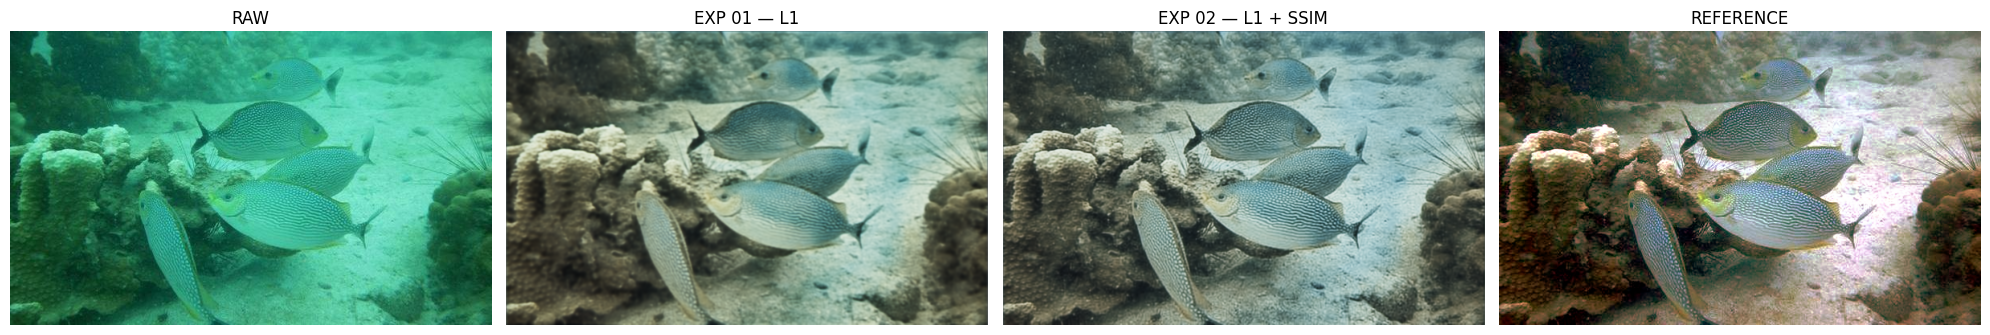

In [91]:
# ============================================================
# TEST ONE UNSEEN IMAGE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Pick first image from test set
test_filename = test_df.iloc[0]["filename"]

raw_path = os.path.join(
    RAW_DIR,
    test_filename
)

reference_path = os.path.join(
    REFERENCE_DIR,
    test_filename
)


# ------------------------------------------------------------
# Load raw + reference
# ------------------------------------------------------------

raw_image = Image.open(
    raw_path
).convert("RGB")

reference_image = Image.open(
    reference_path
).convert("RGB")


raw_np = (
    np.asarray(raw_image)
    .astype(np.float32) / 255.0
)

reference_np = (
    np.asarray(reference_image)
    .astype(np.float32) / 255.0
)


# ------------------------------------------------------------
# Prepare input
# ------------------------------------------------------------

input_tensor, original_width, original_height = (
    load_image_for_model(raw_path)
)

input_tensor = input_tensor.to(device)


# ------------------------------------------------------------
# Experiment 01
# ------------------------------------------------------------

with torch.no_grad():

    output_exp01 = model_exp01(
        input_tensor
    )

output_exp01 = output_exp01[
    :,
    :,
    :original_height,
    :original_width
]

output_exp01 = torch.clamp(
    output_exp01,
    0,
    1
)

exp01_np = (
    output_exp01
    .squeeze(0)
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# Experiment 02
# ------------------------------------------------------------

with torch.no_grad():

    output_exp02 = model_exp02(
        input_tensor
    )

output_exp02 = output_exp02[
    :,
    :,
    :original_height,
    :original_width
]

output_exp02 = torch.clamp(
    output_exp02,
    0,
    1
)

exp02_np = (
    output_exp02
    .squeeze(0)
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# Calculate metrics for this image
# ------------------------------------------------------------

print("=" * 70)
print("SINGLE TEST IMAGE")
print("=" * 70)

print("Filename:", test_filename)
print(
    "Original size:",
    raw_image.size
)

print("\nExperiment 01:")
print(
    "PSNR :",
    f"{calculate_psnr(exp01_np, reference_np):.4f}"
)
print(
    "SSIM :",
    f"{calculate_ssim(exp01_np, reference_np):.4f}"
)
print(
    "UIQM :",
    f"{calculate_uiqm(exp01_np):.4f}"
)
print(
    "UCIQE:",
    f"{calculate_uciqe(exp01_np):.4f}"
)

print("\nExperiment 02:")
print(
    "PSNR :",
    f"{calculate_psnr(exp02_np, reference_np):.4f}"
)
print(
    "SSIM :",
    f"{calculate_ssim(exp02_np, reference_np):.4f}"
)
print(
    "UIQM :",
    f"{calculate_uiqm(exp02_np):.4f}"
)
print(
    "UCIQE:",
    f"{calculate_uciqe(exp02_np):.4f}"
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

axes[0].imshow(raw_np)
axes[0].set_title("RAW")

axes[1].imshow(exp01_np)
axes[1].set_title("EXP 01 — L1")

axes[2].imshow(exp02_np)
axes[2].set_title("EXP 02 — L1 + SSIM")

axes[3].imshow(reference_np)
axes[3].set_title("REFERENCE")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()